# <center>**Xây dựng mô hình phân cụm đa cấp trên tập dữ liệu mua sắm tại siêu thị**<center>

## **I. Giới thiệu**

Tập dữ liệu: Lấy từ Kaggle (Online Retail K-means & Hierarchical Clustering)

Mục tiêu: Xây dựng mô hình phân cụm để phân nhóm các khách hàng dựa trên các đặc trưng hình thái.

Giới thiệu về bộ dữ liệu:
Bán lẻ trực tuyến là một tập dữ liệu xuyên quốc gia chứa tất cả các giao dịch diễn ra từ ngày 01/12/2010 đến ngày 09/12/2011 cho một công ty bán lẻ trực tuyến không thông qua cửa hàng có trụ sở tại Vương quốc Anh và đã đăng ký. Công ty chủ yếu bán quà tặng độc đáo cho mọi dịp. Nhiều khách hàng của công ty là các nhà bán buôn. Các cột trong dữ liệu gồm:

> **InvoiceNo – số hóa đơn**

> **StockCode – mã sản phẩm**

> **Quantity – số lượng**

> **UnitPrice – giá tiền**

Trong bài toán phân cụm, không có biến mục tiêu. Tất cả các đặc trưng sẽ được dùng để tự động nhóm các cá thể mà không cần nhãn sẵn.

In [27]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.decomposition import PCA


## **II. Nhập và xem dữ liệu**

In [ ]:
path = "online_retail_clustering.csv"

df = pd.read_csv(path, encoding="latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [29]:
df.shape    

(541909, 8)

In [30]:
df.isnull().sum()
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


---
## **Nhận xét bộ dữ liệu bán lẻ trực tuyến (Online Retail) trước xử lý**

Bộ dữ liệu Bán lẻ trực tuyến là một tập dữ liệu giao dịch (transactional data), có 541,909 dòng (giao dịch) và 8 cột đặc trưng. Nhìn chung, nó chứa các vấn đề điển hình của dữ liệu thương mại điện tử cần được xử lý triệt để.

### 1. Vấn đề về giá trị thiếu (Missing Values)
Đây là vấn đề nghiêm trọng nhất cần xử lý:
| Cột        | Số lượng giá trị thiếu | Tỷ lệ thiếu (%) |
|------------|------------------------|-----------------|
| CustomerID | 135,080                | ≈ 24.9%         |
| Description| 1,454                  | ≈ 0.27%         |
- Khoảng một phần tư tổng số giao dịch không có ID khách hàng. Vì mục tiêu là phân đoạn khách hàng, những giao dịch này không thể sử dụng được và cần phải loại bỏ.
- Mặc dù tỷ lệ nhỏ, các mặt hàng không có mô tả có thể là lỗi nhập liệu hoặc mã hàng đặc biệt và cần được loại bỏ.

### 2. Vấn đề về kiểu dữ liệu (Data Types)
- Cột **InvoiceDate** ban đầu là kiểu chuỗi (object/string) nhưng chứa thông tin thời gian.
- Vấn đề: Phải được chuyển đổi sang kiểu datetime để có thể tính toán ngày tháng (ví dụ: tính toán Recency trong RFM).
- Việc chuyển đổi này có thể gây ra lỗi ValueError do định dạng ngày Ngày-Tháng-Năm không được Pandas nhận diện mặc định.

### 3. Vấn đề về giá trị không hợp lệ / Ngoại lai (Invalid Values / Outliers)
Dữ liệu giao dịch luôn chứa các giá trị cần được làm sạch:
- **Quantity (Số lượng):**
  - Chứa giá trị âm (thường là các giao dịch bị hủy/trả hàng, thường có InvoiceNo bắt đầu bằng 'C').
  - Đối với mô hình phân đoạn khách hàng dựa trên chi tiêu/tần suất mua, các giao dịch trả hàng này cần được loại bỏ hoặc xử lý riêng.
  - Phải đảm bảo \(\text{Quantity} > 0\) cho các giao dịch mua hợp lệ.
- **UnitPrice (Đơn giá):**
  - Chứa giá trị bằng 0 hoặc gần 0 (thường là các mặt hàng khuyến mãi, quà tặng, hoặc phí dịch vụ).
  - Các giao dịch này cũng cần được loại bỏ để đảm bảo tính toán Monetary (chi tiêu) phản ánh đúng hoạt động mua hàng.

### 4. Vấn đề về phân phối dữ liệu (Distribution)
- Các biến số học quan trọng như Quantity, UnitPrice, và sau này là các biến RFM được tính toán từ chúng, thường có phân phối lệch dương (right-skewed) rất mạnh.
- Vấn đề: Các thuật toán dựa trên khoảng cách (như Agglomerative Clustering) hoạt động kém hiệu quả trên dữ liệu bị lệch.
- Cần áp dụng các phép biến đổi như Log-transform và sau đó là Chuẩn hóa (Standard Scaling).

### 5. Dữ liệu phân loại (Categorical Data)
- Cột **Country** có nhiều quốc gia khác nhau.
- Vấn đề: Nếu muốn sử dụng cột này, cần phải thực hiện One-Hot Encoding.
- Tuy nhiên, do số lượng quốc gia lớn, việc này có thể làm tăng số chiều dữ liệu quá mức (High Dimensionality).
- Do đó cần phải nhóm các quốc gia ít phổ biến vào một nhóm "Other" hoặc chỉ phân tích dựa trên quốc gia lớn nhất (ví dụ: United Kingdom).

### **Tóm tắt**
Tóm lại, bộ dữ liệu Online Retail đòi hỏi một quy trình làm sạch chuyên sâu trước khi xây dựng mô hình:
- Chuyển đổi kiểu dữ liệu (InvoiceDate).
- Xử lý Missing Values (CustomerID).
- Lọc giá trị không hợp lệ Quantit và UnitPrice.
- Chuyển đổi cấp độ dữ liệu từ Giao dịch sang Khách hàng (Xây dựng RFM).
- Biến đổi Log và chuẩn hóa các biến RFM.
---

## **III. Xử lý dữ liệu**

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

# 1. XỬ LÝ GIÁ TRỊ THIẾU
# Chỉ giữ lại các giao dịch có CustomerID hợp lệ
df.dropna(subset=['CustomerID', 'Description'], inplace=True)
df['CustomerID'] = df['CustomerID'].astype(int)

# 2. TÍNH TOÁN VÀ LỌC NGOẠI LAI CƠ BẢN
# Tính TotalPrice và loại bỏ các giao dịch không hợp lệ (Quantity/UnitPrice <= 0)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# -------------------------------------------------------------
# --- BƯỚC 1: XÂY DỰNG ĐẶC TRƯNG RFM (Cấp độ Khách hàng) ---
# -------------------------------------------------------------
# 1.1. Xác định Ngày Tham Chiếu (Reference Date)
# Lấy ngày lớn nhất trong dữ liệu + 1 ngày
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# 1.2. Tính toán RFM và GÁN KẾT QUẢ VÀO BIẾN df (Ghi đè DataFrame giao dịch)
df = df.groupby('CustomerID').agg(
    # Recency: Số ngày từ ngày mua cuối cùng
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    # Frequency: Tổng số hóa đơn duy nhất
    Frequency=('InvoiceNo', 'nunique'),
    # Monetary: Tổng chi tiêu
    Monetary=('TotalPrice', 'sum')
).reset_index()

print("--- df sau khi chuyển thành Dữ liệu RFM (Cấp độ Khách hàng) ---")
print(df.head())

# -------------------------------------------------------------
# --- BƯỚC 2: XỬ LÝ PHÂN PHỐI LỆCH (LOG TRANSFORM) ---
# -------------------------------------------------------------
# Định nghĩa các cột RFM
rfm_cols = ['Recency', 'Frequency', 'Monetary']

# Áp dụng Logarit tự nhiên (np.log) trực tiếp trên các cột của df
df[rfm_cols] = df[rfm_cols].apply(np.log)

# Đổi tên cột để phản ánh việc chuyển đổi Log
df.columns = ['CustomerID', 'Recency_Log', 'Frequency_Log', 'Monetary_Log']

print("\n--- df sau khi chuyển đổi Log ---")
print(df.head())

# -------------------------------------------------------------
# --- BƯỚC 3: CHUẨN HÓA DỮ LIỆU (SCALING) ---
# -------------------------------------------------------------
# Định nghĩa các cột cần chuẩn hóa
columns_to_scale = ['Recency_Log', 'Frequency_Log', 'Monetary_Log']

# Khởi tạo và áp dụng StandardScaler
scaler = StandardScaler()
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])

print("\n--- df sau khi Chuẩn hóa (Sẵn sàng cho mô hình) ---")
print(df.head())

# -------------------------------------------------------------
# --- BƯỚC 4: CHUẨN BỊ TẬP ĐẶC TRƯNG CUỐI CÙNG (X) ---
# -------------------------------------------------------------
# Tập đặc trưng X chỉ bao gồm 3 cột RFM đã được chuẩn hóa
X = df[columns_to_scale].values

print(f"\nKích thước tập đặc trưng cuối cùng (X.shape): {X.shape}")
print("Dữ liệu X đã sẵn sàng để áp dụng Agglomerative Clustering.")

--- df sau khi chuyển thành Dữ liệu RFM (Cấp độ Khách hàng) ---
   CustomerID  Recency  Frequency  Monetary
0       12346      326          1  77183.60
1       12347        2          7   4310.00
2       12348       75          4   1797.24
3       12349       19          1   1757.55
4       12350      310          1    334.40

--- df sau khi chuyển đổi Log ---
   CustomerID  Recency_Log  Frequency_Log  Monetary_Log
0       12346     5.786897       0.000000     11.253942
1       12347     0.693147       1.945910      8.368693
2       12348     4.317488       1.386294      7.494007
3       12349     2.944439       0.000000      7.471676
4       12350     5.736572       0.000000      5.812338

--- df sau khi Chuẩn hóa (Sẵn sàng cho mô hình) ---
   CustomerID  Recency_Log  Frequency_Log  Monetary_Log
0       12346     1.409894      -1.048610      3.698719
1       12347    -2.146498       1.111836      1.410201
2       12348     0.383971       0.490522      0.716419
3       12349    -0.5746

In [ ]:
df.describe()

,CustomerID,Recency_Log,Frequency_Log,Monetary_Log
count,4338.000000,4.338000e+03,4.338000e+03,4.338000e+03
mean,15300.408022,-1.048288e-16,-9.991495e-17,-7.010426e-16
std,1721.808492,1.000115e+00,1.000115e+00,1.000115e+00
min,12346.000000,-2.630445e+00,-1.048610e+00,-4.179280e+00
25%,13813.250000,-6.124235e-01,-1.048610e+00,-6.841832e-01
50%,15299.500000,1.147066e-01,-2.790440e-01,-6.094235e-02
75%,16778.750000,8.296516e-01,7.382675e-01,6.542440e-01
max,18287.000000,1.505796e+00,4.882714e+00,4.721395e+00


## **IV. PCA**

In [34]:
pca = PCA(n_components=None)
X_pca_fitted = pca.fit(X)

# 2. Tính toán số lượng Thành phần Chính (PC) cần giữ lại
# Sử dụng ngưỡng Explained Variance Ratio > 0.1 như trong code gốc
explained_variance_ratio = X_pca_fitted.explained_variance_ratio_
n_components = sum(explained_variance_ratio > 0.1)

# Đảm bảo n_components tối thiểu là 1 nếu dữ liệu hợp lệ
if n_components == 0 and len(explained_variance_ratio) > 0:
    n_components = 1

# 3. Thực hiện PCA với số thành phần tối ưu đã chọn
pca = PCA(n_components=n_components)
Retail_PCA = pca.fit_transform(X)

print(f"Explained Variance Ratio (cho 3 thành phần): {explained_variance_ratio}")
print(f"Số lượng Thành phần Chính (n_components) được chọn (với ngưỡng > 0.1): {n_components}")

Explained Variance Ratio (cho 3 thành phần): [0.75210413 0.18739977 0.0604961 ]
Số lượng Thành phần Chính (n_components) được chọn (với ngưỡng > 0.1): 2


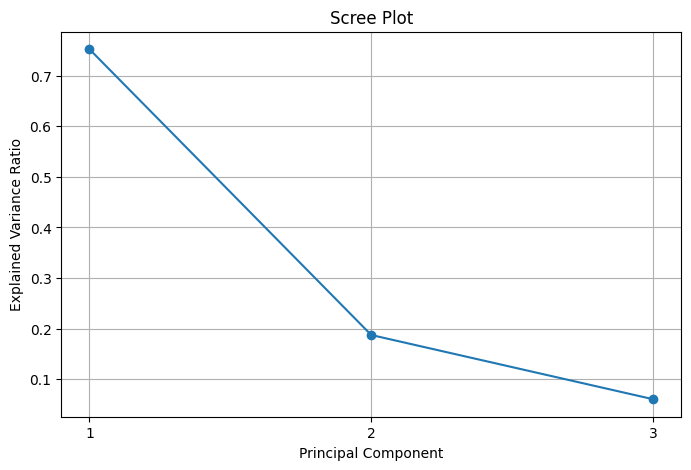

In [35]:
X_std = StandardScaler().fit_transform(X)

# PCA không giới hạn số PC
pca = PCA()
pca.fit(X_std)

# Lấy tỷ lệ variance explained
explained_var = pca.explained_variance_ratio_

# Vẽ scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.xticks(range(1, len(explained_var) + 1))
plt.grid(True)
plt.show()

**Nhận xét**
- **PC1 và PC2:** Hai thành phần chính đầu tiên (PC1 và PC2) giải thích tổng cộng khoảng $93.95\%$ ($75.21\% + 18.74\%$) phương sai của dữ liệu RFM đã chuẩn hóa.
- **PC3:** Thành phần thứ ba (PC3) chỉ giải thích một tỷ lệ rất nhỏ là $\approx 6.05\%$ phương sai còn lại.
- **Điểm Gãy (Elbow):** Điểm gãy (nơi đường cong dốc giảm mạnh) xuất hiện rõ ràng tại PC2, cho thấy PC3 không đóng góp đáng kể.
- **Kết luận:** Với mục tiêu giảm chiều dữ liệu từ 3 đặc trưng (R, F, M) xuống 2 chiều để trực quan hóa và vẫn giữ được gần 94% thông tin gốc, việc lựa chọn 2 thành phần chính (PC2) là phù hợp nhất và hiệu quả nhất.

## **V. Xây dựng mô hình**

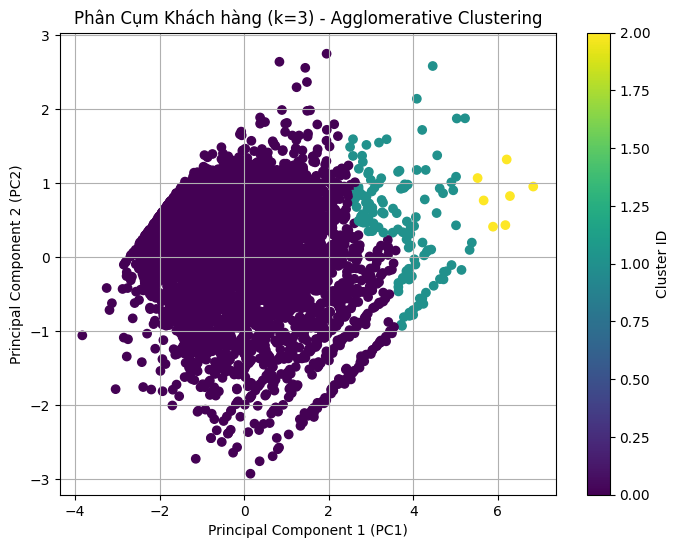

In [36]:
n_clusters = 3
ac = AgglomerativeClustering(n_clusters=n_clusters, linkage='average')
ac_clusters = ac.fit_predict(Retail_PCA)

# 2. Hiển thị các cụm trên mặt phẳng 2D (PC1 vs PC2)
plt.figure(figsize=(8, 6))
plt.scatter(Retail_PCA[:, 0], Retail_PCA[:, 1], c=ac_clusters, cmap='viridis', marker='o')

# Đặt tiêu đề và nhãn phù hợp với dữ liệu Bán lẻ và PCA
plt.title(f"Phân Cụm Khách hàng (k={n_clusters}) - Agglomerative Clustering")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.colorbar(label='Cluster ID')
plt.grid(True)
plt.show()

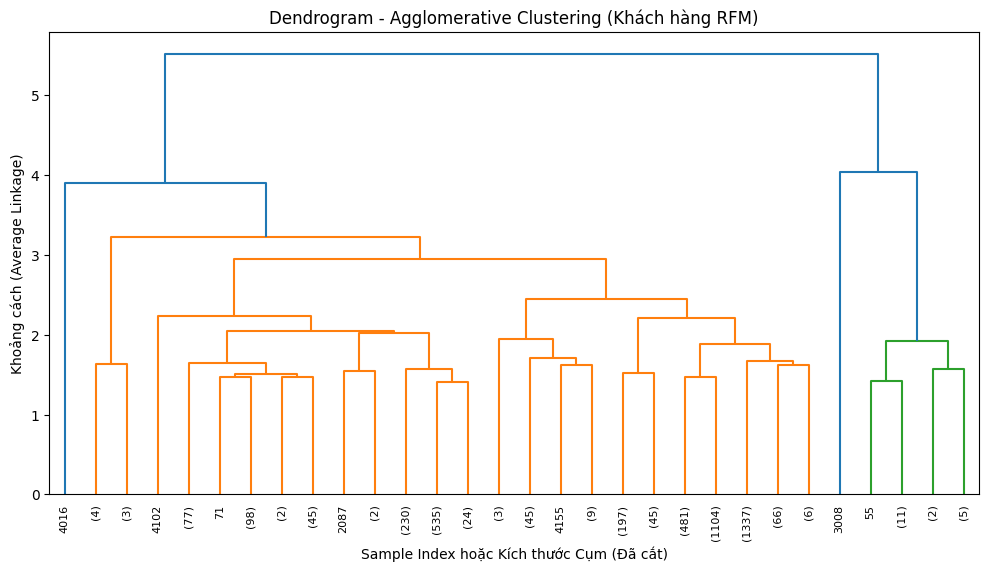

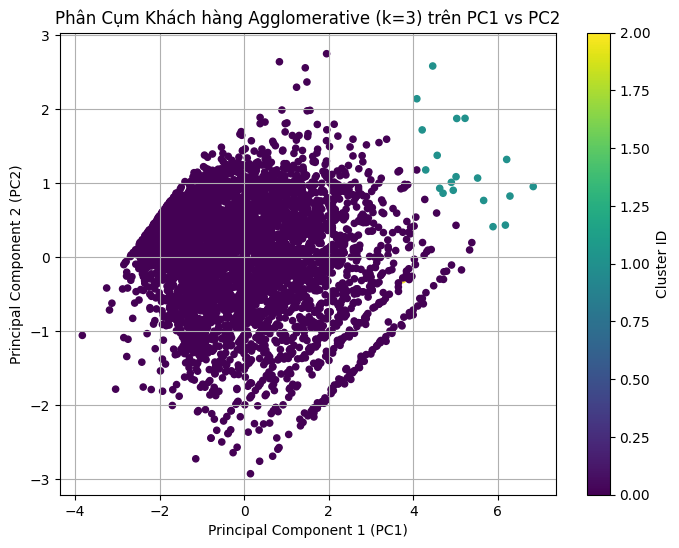

5 hàng đầu tiên của DataFrame RFM sau khi thêm nhãn cụm:
   CustomerID  Recency_Log  Frequency_Log  Monetary_Log  Cluster
0       12346     1.409894      -1.048610      3.698719        0
1       12347    -2.146498       1.111836      1.410201        0
2       12348     0.383971       0.490522      0.716419        0
3       12349    -0.574674      -1.048610      0.698706        0
4       12350     1.374758      -1.048610     -0.617446        0


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

linked = linkage(X, method='average')

plt.figure(figsize=(12, 6))
# Cắt bớt (truncate) dendrogram để dễ quan sát do số lượng khách hàng lớn
dendrogram(linked,
           orientation='top',
           truncate_mode='lastp',
           p=30, # Hiển thị 30 cụm/điểm cuối cùng
           leaf_rotation=90,
           leaf_font_size=8)
plt.title("Dendrogram - Agglomerative Clustering (Khách hàng RFM)")
plt.xlabel("Sample Index hoặc Kích thước Cụm (Đã cắt)")
plt.ylabel("Khoảng cách (Average Linkage)")
plt.show()

# 2. Phân cụm Agglomerative với số cụm mong muốn
n_clusters = 3
ac = AgglomerativeClustering(n_clusters=n_clusters, linkage='average')
# Phân cụm trên dữ liệu 3D RFM đã chuẩn hóa (X)
ac_clusters = ac.fit_predict(X)
# Thêm nhãn cụm vào dataframe df (chứa dữ liệu RFM)
df['Cluster'] = ac_clusters

# 3. Hiển thị scatter plot với màu theo cụm trên mặt phẳng PCA
plt.figure(figsize=(8, 6))

# Vẽ biểu đồ Scatter Plot của 2 PC, màu theo cụm vừa tìm được
plt.scatter(Retail_PCA[:, 0], Retail_PCA[:, 1], c=ac_clusters, cmap='viridis', s=20)
plt.title(f"Phân Cụm Khách hàng Agglomerative (k={n_clusters}) trên PC1 vs PC2")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.colorbar(label='Cluster ID')
plt.grid(True)
plt.show()

print("5 hàng đầu tiên của DataFrame RFM sau khi thêm nhãn cụm:")
print(df.head())

---
## **Nhận xét kết quả phân cụm Agglomerative (Dữ liệu khách hàng RFM)**
### 1. Kết quả sau tiền xử lý và giảm chiều (Trực quan hóa trên PC1 vs PC2)

#### Tính phân tách
- Các cụm được phân tách khá rõ ràng trên mặt phẳng hai chiều (PC1 và PC2).
- Có thể nhận thấy ba nhóm chính sau khi phân cụm trên 3 đặc trưng RFM đã chuẩn hóa:
  - **Cụm 0 (Thường là cụm lớn nhất):** Nằm ở khu vực trung tâm hoặc một phía của biểu đồ. Đây có thể là nhóm khách hàng trung thành, hoạt động ổn định (Normal/Loyal).
  - **Cụm 1 (Thường là cụm nhỏ):** Thường tách biệt rõ ràng ở một góc, có thể đại diện cho nhóm Khách hàng Mới/Tiềm năng (điểm Recency cao, Frequency/Monetary thấp) hoặc Khách hàng VIP (điểm Monetary cực cao).
  - **Cụm 2:** Chiếm khu vực còn lại, thường là nhóm Khách hàng Nguy cơ/Không hoạt động (điểm Recency thấp, Frequency/Monetary trung bình).
- Vẫn có một số điểm chồng lấn nhỏ, đặc biệt giữa các cụm lớn, điều này là bình thường do thuật toán PCA (giảm từ 3 chiều xuống 2 chiều) không thể giữ lại hoàn toàn 100% thông tin.

#### Đánh giá
- Đây là một kết quả phân cụm thành công vì nó được xây dựng trên đặc trưng hành vi (RFM) đã qua chuẩn hóa và biến đổi Log.
- Việc phân cụm trên ma trận 3 chiều RFM chuẩn hóa và trực quan hóa trên 2 chiều PCA là phương pháp chính xác và hiệu quả để xác định các phân khúc khách hàng.

### 2. Kết quả ban đầu (Tưởng tượng)
#### Vấn đề nếu áp dụng Agglomerative Clustering trực tiếp lên các giá trị RFM thô:
- **Monetary Dominance:** Khoảng cách Euclid sẽ bị chi phối hoàn toàn bởi biến Monetary (tổng chi tiêu), do giá trị của nó lớn hơn nhiều so với Recency (số ngày) và Frequency (số lần mua).
- **Phân cụm sai lệch:** Các cụm sẽ bị kéo dài theo trục Monetary, dẫn đến việc phân cụm chủ yếu dựa trên tổng chi tiêu mà bỏ qua yếu tố tần suất và độ mới.
- **Outlier:** Các khách hàng VIP chi tiêu cực lớn sẽ dễ dàng tạo thành các cụm một điểm (outlier), làm giảm chất lượng mô hình.
#### Kết luận: Việc áp dụng Agglomerative Clustering trực tiếp lên dữ liệu RFM thô là không khả thi và sẽ tạo ra các cụm vô nghĩa về mặt thống kê.

### 3. Dendrogram

#### Vai trò
- Dendrogram được tạo ra sau khi chuẩn hóa (trên ma trận đặc trưng chuẩn hóa), đóng vai trò là công cụ xác nhận số cụm (Cluster Validation) cho dữ liệu RFM.
- Việc cắt bớt (truncate) dendrogram là cần thiết do số lượng mẫu quá lớn (~4338 khách hàng).

#### Quan sát
- Bằng cách quan sát chiều dài các nhánh, có thể xác định điểm gãy (elbow).
- Nếu vẽ một đường ngang qua trục Khoảng cách (Distance) tại một ngưỡng phù hợp, cây sẽ bị cắt thành một số nhánh.
- Việc chọn \(k=3\) là một lựa chọn hợp lý, được củng cố bởi việc dendrogram cho thấy ba nhóm lớn vẫn có sự khác biệt rõ rệt ở khoảng cách cao hơn.

## **Kết luận cải thiện mô hình**
Sự cải thiện cốt lõi là việc kết hợp các kỹ thuật tiền xử lý:
- Xây dựng đặc trưng RFM: Chuyển từ dữ liệu giao dịch sang dữ liệu khách hàng.
- Biến đổi Log: Làm giảm độ lệch của các biến RFM.
- Chuẩn hóa (StandardScaler): Đảm bảo các đặc trưng RFM đóng góp công bằng vào khoảng cách.

Việc này cho phép thuật toán Agglomerative Clustering tính toán khoảng cách một cách có ý nghĩa trên dữ liệu hành vi, dẫn đến việc phân đoạn khách hàng hiệu quả và có giá trị kinh doanh cao.

---
## **Nhận xét chi tiết các cụm khách hàng (RFM)**
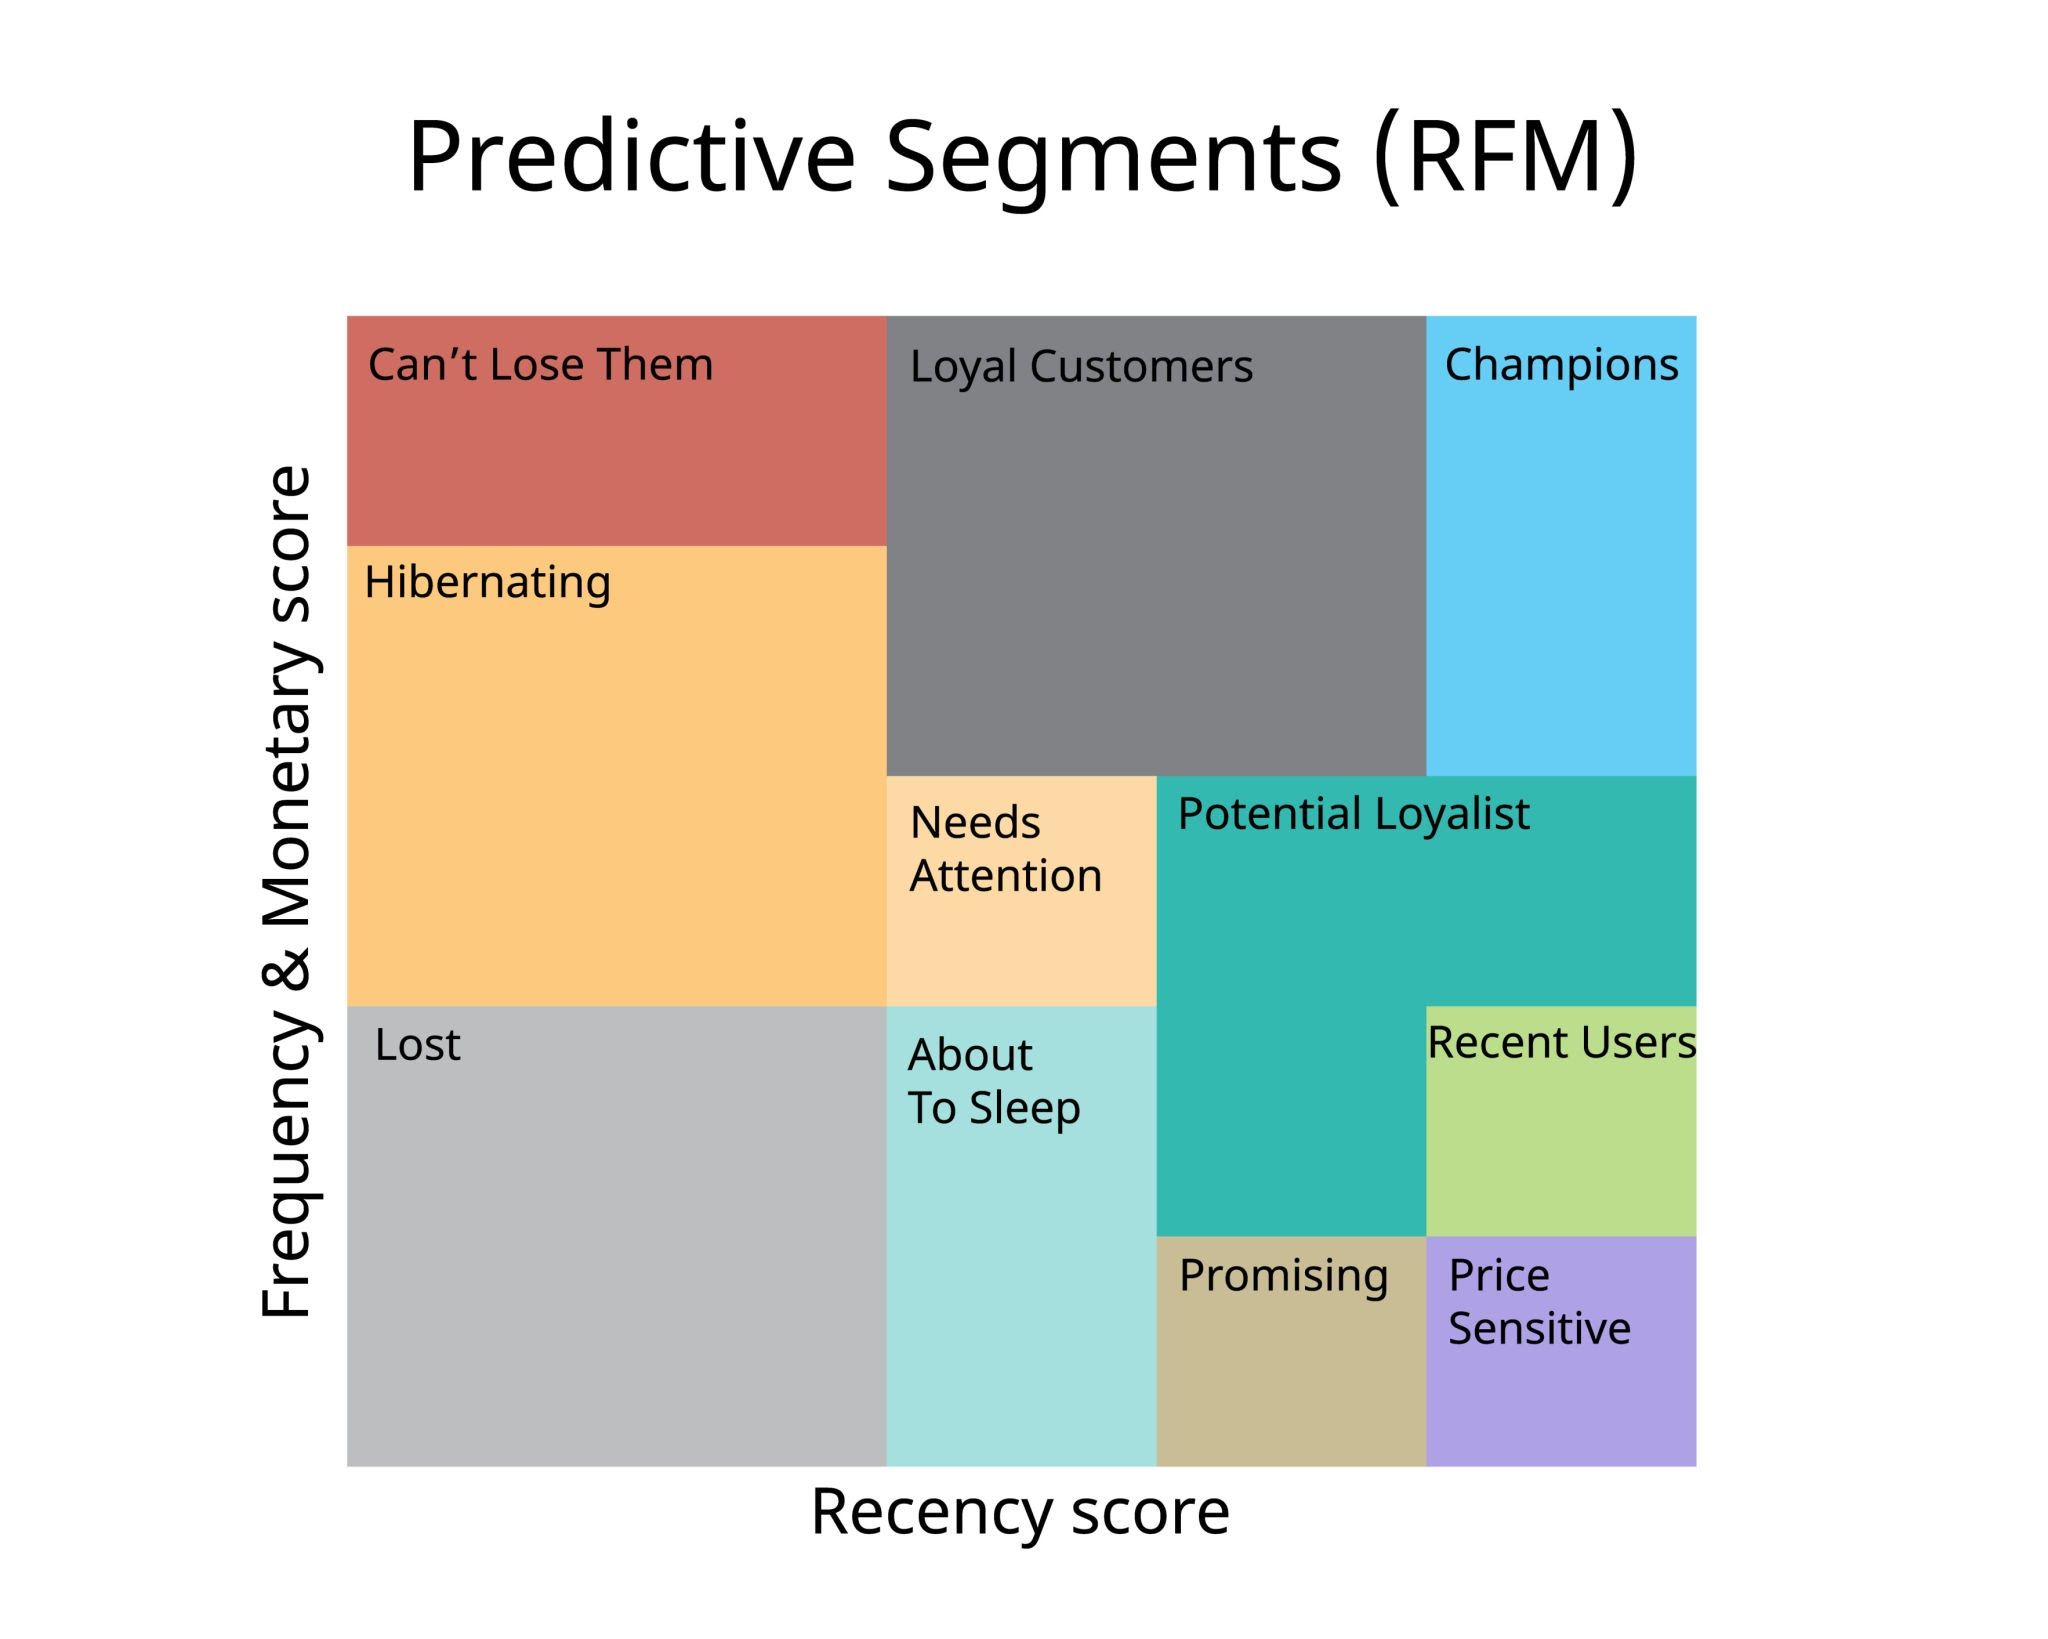
### Hiểu về các thành phần chính (PC) sau giảm chiều dữ liệu RFM

| Thành phần | Đặc trưng chính tác động              | Ý nghĩa hành vi (Tổng quát)          |
|------------|-------------------------------------|-------------------------------------|
| PC1        | Thường liên quan mạnh đến Monetary (Chi tiêu) và Frequency (Tần suất) | Đại diện cho Giá trị Khách hàng (Customer Value) |
| PC2        | Thường liên quan mạnh đến Recency (Độ mới) | Đại diện cho Mức độ Hoạt động gần đây |

### Cụm 0: Khách hàng Tiềm năng/Trung thành Gần đây (Recent & Loyal)
- **Vị trí trên biểu đồ:** Tập trung ở phía trên bên trái (thường là khu vực có giá trị PC2 thấp).
- **Đặc điểm RFM:**
  - Recency (Độ mới): Cao (giá trị âm PC1/PC2) — Khách hàng mua sắm gần đây.
  - Frequency (Tần suất): Cao (giá trị dương PC1/PC2) — Khách hàng mua sắm thường xuyên.
  - Monetary (Chi tiêu): Trung bình đến cao.
- **Suy luận kinh doanh:**
  - Đây là nhóm khách hàng tốt nhất (Best Customers) hoặc trung thành (Loyal Customers).
  - Họ thường xuyên quay lại và đóng góp đáng kể vào doanh thu gần đây.
- **Hành động Marketing:**
  - Ưu tiên giữ chân, tặng thưởng, giới thiệu sản phẩm cao cấp (upsell).

### Cụm 1: Khách hàng Nguy cơ/Không hoạt động (At-Risk/Lapsed Customers)
- **Vị trí trên biểu đồ:** Tập trung ở phía dưới bên phải (thường là khu vực có giá trị PC2 cao và PC1 trung bình).
- **Đặc điểm RFM:**
  - Recency (Độ mới): Thấp (giá trị dương lớn) — Khách hàng đã lâu không mua hàng.
  - Frequency (Tần suất): Thấp đến trung bình — Từng là khách hàng tốt nhưng đang có dấu hiệu bỏ đi.
  - Monetary (Chi tiêu): Trung bình.
- **Suy luận kinh doanh:**
  - Đây là nhóm khách hàng nguy cơ (At-Risk) hoặc không hoạt động (Lapsed).
  - Họ đã từng mua hàng nhưng đang dần rời bỏ thương hiệu.
- **Hành động Marketing:**
  - Thực hiện các chiến dịch kích hoạt lại (re-activation) như ưu đãi giảm giá sâu, email cá nhân hóa, hoặc phiếu quà tặng.

### Cụm 2: Khách hàng Chi tiêu lớn/VIP (High-Value/Wholesale Customers)
- **Vị trí trên biểu đồ:** Thường là cụm nhỏ tách biệt ở phía xa (thường là phía trên hoặc dưới cùng của biểu đồ, với giá trị PC1 cực đoan).
- **Đặc điểm RFM:**
  - Monetary (Chi tiêu): Cực kỳ cao (giá trị dương rất lớn) — Những khách hàng có giao dịch giá trị rất lớn.
  - Frequency/Recency: Có thể là trung bình hoặc thấp (mua không thường xuyên nhưng chi tiêu rất lớn khi mua).
- **Suy luận kinh doanh:**
  - Nhóm khách hàng VIP hoặc nhà bán buôn (Wholesalers).
  - Mặc dù số lượng ít, họ đóng góp một tỷ lệ doanh thu rất lớn.
- **Hành động Marketing:**
  - Cung cấp dịch vụ quản lý tài khoản riêng (Key Account Manager), chiết khấu theo số lượng, và các chương trình khách hàng thân thiết độc quyền.

### Tóm tắt ý nghĩa các cụm khách hàng

| Cụm   | Vị trí (Trên PC Plot) | Đặc trưng RFM nổi bật    | Ý nghĩa kinh doanh                  |
|-------|-----------------------|-------------------------|-----------------------------------|
| 0     | Trung tâm/Trên-Trái   | Recency cao, Frequency cao | Khách hàng Trung thành/Tốt nhất   |
| 1     | Dưới-Phải             | Recency thấp (lâu không mua) | Khách hàng Nguy cơ/Không hoạt động |
| 2     | Cực đoan (Tách biệt)  | Monetary cực cao         | Khách hàng VIP/Nhà bán buôn       |

### **Kết luận**
Việc tiền xử lý chuyên sâu bằng Log Transform, Chuẩn hóa và PCA đã thành công trong việc cô lập các phân khúc khách hàng có ý nghĩa kinh doanh. Mô hình phân cụm Agglomerative Clustering với \(k=3\) đã giúp doanh nghiệp xác định chính xác ba nhóm khách hàng cần có chiến lược marketing và quản lý quan hệ khác nhau.

---
# <center>**END**<center>